# 06 - A dark-matter search end to end: likelihood, profiling, limits

This notebook assembles the components of the previous tutorials into a small rudimentary 
Galactic-Centre dark-matter analysis and shows the statistical tools the library provides for it:

1. a forward model with a **point source**, an **isotropic** component (a stand-in for diffuse
   emission), **dark-matter annihilation** and the **cosmic-ray background**;
2. two Asimov data sets: a background only, and one with a thermal-relic signal injected;
3. the Poisson log-likelihood, evaluated for **batches** of parameter values with autograd support;
4. **profiling** of the nuisance parameters over a grid in $(m_\chi, \langle\sigma v\rangle)$: the
   nuisance parameters are template amplitudes, so their gradient and Hessian are analytic and the whole
   grid is fitted in a few seconds, with and without a **per-energy-bin background systematic**;
5. the **median expected 95 % CL upper limit** versus mass (statistics only and with a 1 %
   background systematic), the **detection significance** of the injected signal and its
   **confidence region**, a check of the **Laplace approximation** against the profile, and one
   **Poisson realisation**.

The results will notably be *optimistic*, to put it lightly. DO NOT use them as actual limits.
Expect a few minutes on a laptop CPU (`GAMMABAYES_DOCS_FAST=1` for a coarser, faster version).



Keep these in mind before reading the numbers as a CTAO sensitivity. The numbers reported here are not official, or even realistic. 
They are purely to get an idea of the pipeline. Some reasons as to why the approach detailed in this notebook is very rudimentary are:

* **Background model.**  The only diffuse emission is an isotropic power law; the real Galactic
  Centre has structured diffuse emission (GALPROP / Fermi templates, the ridge) and more point
  sources, all of which degrade the limit.
* **Systematic uncertainties.**  Only a per-energy-bin background normalisation (1 % Gaussian
  constraint) is included, and only in the second set of limits.  Spatially structured systematics (a
  $\sigma_\mathrm{S}$-level modulation with a correlation length) and the uncertainty on the IRFs
  themselves are what limit real IACT analyses at high counts; they enter as further nuisance fields
  in the likelihood.
* **Asymptotics.**  Wilks' theorem is used for both the limit and the significance.  With
  $3\times10^6$ counts the asymptotic regime is reached for the amplitude-like parameters, but the
  significance quoted for the injected signal ignores the look-elsewhere effect over the mass axis.
* **Grid resolution.**  Limits are interpolated on a $\langle\sigma v\rangle$ grid of 0.1 dex; refine
  the grid or run a 1-D root finder on `profile` for publication-quality numbers.
* **Statistics vs Bayesian inference.**  The notebook uses frequentist profile likelihoods.  The
  same `loglike` and its autograd gradients drive Bayesian samplers (Laplace-initialised
  importance sampling, HMC through pyro, normalising-flow proposals) when priors on the nuisance
  parameters are available. Not to say that "frequentist = bad", just that it won't match other more
  detailed and well-checked results that come out of this pipeline that take into account the full
  probability space while taking into account the increased parameter space.
* **Livetime** We also use a livetime of 50h, less than the currently planned KSP time for the CTAO
  GC survey. Mostly so there is even less confusion with published `GammaBayes` results.


For a more complete analysis we recommend looking at our most recent paper. (The one using the most recent version of the code with well-motivated priors is coming out soon called "How Can We Be Sure".)

In [1]:
import os, math, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
import numpy as np
import torch
import matplotlib.pyplot as plt
from astropy import units as u

FAST = os.environ.get("GAMMABAYES_DOCS_FAST", "0") == "1"

# device: GAMMABAYES_DOCS_DEVICE=cpu|cuda|mps, else CUDA > Apple MPS > CPU.  MPS has no float64 (as of writing), so it runs in float32.
device = os.environ.get("GAMMABAYES_DOCS_DEVICE") or ("cuda" if torch.cuda.is_available()
                                                      else "mps" if torch.backends.mps.is_available() else "cpu")
if device == "mps":
    # the profile-likelihood Newton steps and the autograd Hessians of this notebook need float64,
    # which the Metal backend does not provide: run this one on the CPU
    print("Apple MPS has no float64; this notebook's statistics need it, so it runs on the CPU.")
    device = "cpu"
torch.set_default_dtype(torch.float64)
torch.set_default_device(device)                # GammaBayes objects are created on the default device
print(f"torch {torch.__version__} on {device} ({torch.get_default_dtype()}), FAST={FAST}")

from gammabayes import GammaBinning, GammaLogExposure
from gammabayes.core.batching import as_param, batch_size, iter_batch_chunks
from gammabayes.response_functions import IRFExtractor
from gammabayes.utils import IRFForwardConv, make_forward_irf_kernels
from gammabayes.priors import TwoCompFluxPrior, StaticSourceDistTemplate
from gammabayes.priors.spectral_components import PowerLaw
from gammabayes.priors.spatial_components import PointSpatial_PriorComp
from gammabayes.priors.astro_sources import IsotropicPowerLaw
from gammabayes.dark_matter import Einasto_Profile, CustomDMRatiosModel
npy = lambda t: t.detach().cpu().numpy()

half, res = (1.5, 8) if FAST else (2.0, 10)   # 16 bins/deg costs 2.6x per likelihood evaluation
geom = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100.,
                    lon_res=res, lon_min=-half, lon_max=half, lat_res=res, lat_min=-half, lat_max=half)
pointing = torch.tensor([0., 0.])
irfs = IRFExtractor(zenith_angle=20, hemisphere="South", prod_vers=5, pointing_dir=pointing, irf_time_seconds=180000)
E = geom.energy_axis
print("analysis grid (E, lon, lat):", geom.shape)

Apple MPS has no float64; this notebook's statistics need it, so it runs on the CPU.
torch 2.15.0 on cpu (torch.float64), FAST=False


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


analysis grid (E, lon, lat): (30, 40, 40)


[wall time: 3.2 s]


## 1. The model

| component | where it lives | parameters |
|---|---|---|
| GC point source, power law (index 2.3) | true grid → forward operator | amplitude $A_\mathrm{GC}$ |
| isotropic power law (diffuse stand-in) | true grid → forward operator | amplitude $A_\mathrm{iso}$ |
| DM annihilation, $W^+W^-$, Einasto ($\alpha_\mathrm{E} = 0.17$) | true grid → forward operator | $m_\chi$, $\langle\sigma v\rangle$ (parameters of interest) |
| cosmic-ray background (CCR) | reconstructed grid, added after the operator | amplitude $A_\mathrm{CCR}$, or one per energy bin |

The amplitudes are **nuisance parameters** (equal to one at the truth); the two DM parameters are the
**parameters of interest**.  The live time is 50 h.  `model_log_counts` below is the general,
differentiable form of the model (it also lets the point-source index float) and is used for the
batched-likelihood and autograd demonstrations; the profiling in section 4 uses the same components as
fixed templates.

In [2]:
bwE = float(torch.log10(geom.energy_edges[1]) - torch.log10(geom.energy_edges[0]))
bwL = float(geom.lon_edges[1] - geom.lon_edges[0])
bwB = float(geom.lat_edges[1] - geom.lat_edges[0])
nE = max(1, math.ceil(4.0 * 0.09 / bwE))
sigma_t = irfs.psf_sigma_vs_energy(geom.padded((nE, 0, 0)), fraction=0.68, weighting="aeff", pointing_dir=pointing, pixel_floor=False)
kE, kS = make_forward_irf_kernels(bwE, bwL, bwB, log10E_std=0.09, lon_std=sigma_t, lat_std=sigma_t, clearance=4.0)
op = IRFForwardConv(kE, kS, max_batch=64)
tg = geom.padded(op.pads)

live = 50 * u.hr
tlogexp = GammaLogExposure(binning_geometry=tg, irfs=irfs, pointing_dirs=[pointing], live_times=live)
logexp_noaeff = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[pointing], live_times=live, use_log_aeff=False)

gc = TwoCompFluxPrior(spectral_comp=PowerLaw(index=2.3, phi0=2.5e-12), spatial_comp=PointSpatial_PriorComp(),
                      binning_geometry=tg, log_exposure_map=tlogexp, name="GC")
iso = IsotropicPowerLaw(binning_geometry=tg, index=2.4, phi0=2e-14, log_exposure_map=tlogexp)
dm = CustomDMRatiosModel(binning_geometry=tg, channels=["W+W-"], spatial_profile=Einasto_Profile,
                         irf_loglike=irfs, log_exposure_map=tlogexp, name="DM")
g = geom.shaped_grid
log_ccr_rate = irfs.log_bkg_CCR(g[..., 0].flatten(), g[..., 1].flatten(), g[..., 2].flatten(), pointing_dir=pointing).reshape(geom.shape)
ccr = StaticSourceDistTemplate(source_flux_tensor_logtemplate=log_ccr_rate, binning_geometry=geom, log_exposure_map=logexp_noaeff, name="CCR")

log_ccr = ccr.eval_log_on_geom()                       # (E, lon, lat), reconstructed space, parameter free
log_iso = iso.eval_log_on_geom(squeeze=False)          # (1, E_t, lon_t, lat_t), parameter free apart from its amplitude

NUISANCE = ("logA_gc", "index", "logA_iso", "logA_ccr")
NUISANCE_TRUTH = torch.tensor([0.0, 2.3, 0.0, 0.0])
SV_INJECT, M_INJECT = 2.2e-26, 1.0                     # thermal-relic cross section, 1 TeV


def model_log_counts(mass, sigmav, logA_gc, index, logA_iso, logA_ccr):
    """Reconstructed-space log expected counts, (B, E, lon, lat).  Every argument may be a scalar or (B,)."""
    B = batch_size(mass, sigmav, logA_gc, index, logA_iso, logA_ccr)
    col = lambda v: as_param(v, 3).expand(B, 1, 1, 1)
    lg = gc.eval_log_on_geom(spectral_params={"index": index}, spatial_params={"pos_lon": 0., "pos_lat": 0.}, squeeze=False) + col(logA_gc)
    ld = dm.eval_log_on_geom(spectral_params={"mass": mass, "sigmav": sigmav, "ratios": {"W+W-": 1.}},
                             spatial_params={"alpha": 0.17}, squeeze=False)
    true = torch.logaddexp(torch.logaddexp(lg, log_iso + col(logA_iso)), ld)
    return torch.logaddexp(op(true), log_ccr[None] + col(logA_ccr))


def nuisance_kwargs(nu):
    """(B, 4) tensor -> keyword arguments."""
    return {k: nu[:, i] for i, k in enumerate(NUISANCE)}


t0 = time.time()
lam_bkg = model_log_counts(M_INJECT, 0.0, *NUISANCE_TRUTH)[0]
lam_sig = model_log_counts(M_INJECT, SV_INJECT, *NUISANCE_TRUTH)[0]
print(f"one model evaluation: {(time.time() - t0) / 2:.2f} s")
for name, cube in (("GC point source", gc.eval_log_on_geom(spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.})),
                   ("isotropic", log_iso[0]),
                   ("DM, m = 1 TeV, <sigma v> = 2.2e-26", dm.eval_log_on_geom(spectral_params={"mass": M_INJECT, "sigmav": SV_INJECT, "ratios": {"W+W-": 1.}}, spatial_params={"alpha": 0.17})),
                   ("CCR background", log_ccr)):
    print(f"  {name:36s} {float(torch.exp(cube).sum()):11.4g} expected counts")
print(f"reconstructed total: background only {float(torch.exp(lam_bkg).sum()):.6g}, with signal {float(torch.exp(lam_sig).sum()):.6g}")

one model evaluation: 0.03 s
  GC point source                        2.967e+04 expected counts
  isotropic                                   6767 expected counts
  DM, m = 1 TeV, <sigma v> = 2.2e-26      1.07e+04 expected counts
  CCR background                         3.003e+06 expected counts
reconstructed total: background only 3.02686e+06, with signal 3.03189e+06


[wall time: 1.2 s]


## 2. Data

An **Asimov** data set is the expected-counts cube itself: fitting it returns the input parameters
exactly and the likelihood ratios it produces are the *median* ones over an ensemble of
experiments (Cowan et al. 2011).  Two are used below: background only (for the expected limit)
and with a signal injected at the thermal-relic cross section (for detection and recovery).  A
Poisson realisation is one `torch.poisson` call away; one is kept for the final section.

Asimov background-only total: 3.02686e+06   with signal: 3.03189e+06   (one Poisson realisation: 3033646)


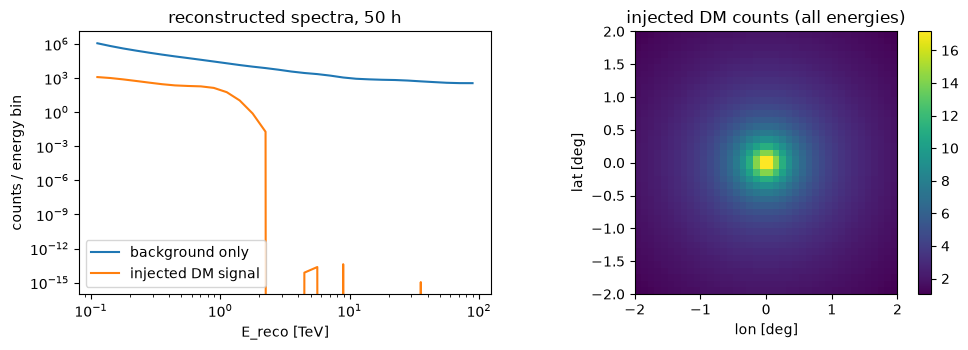

[wall time: 356 ms]


In [3]:
n_bkg = torch.exp(lam_bkg)
n_sig = torch.exp(lam_sig)
torch.manual_seed(42)
n_sig_poisson = torch.poisson(n_sig)
print("Asimov background-only total: %.6g   with signal: %.6g   (one Poisson realisation: %d)" % (n_bkg.sum(), n_sig.sum(), n_sig_poisson.sum()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].loglog(npy(E), npy(n_bkg.sum((1, 2))), label="background only")
ax[0].loglog(npy(E), npy((n_sig - n_bkg).sum((1, 2))), label="injected DM signal")
ax[0].set(xlabel="E_reco [TeV]", ylabel="counts / energy bin", title="reconstructed spectra, 50 h")
ax[0].legend()
excess = (n_sig - n_bkg).sum(0)
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), npy(excess).T, shading="auto")
ax[1].set(xlabel="lon [deg]", ylabel="lat [deg]", aspect="equal", title="injected DM counts (all energies)")
plt.colorbar(pcm, ax=ax[1])
plt.tight_layout()

## 3. The likelihood

Every bin is Poisson distributed, so

$$\ln\mathcal{L}(\theta) - \ln\mathcal{L}_\mathrm{sat}
  = \sum_{r} \Big[\, n_r \ln\frac{\lambda_r(\theta)}{n_r} - \big(\lambda_r(\theta) - n_r\big)\Big].$$

The constant saturated-model term ($\lambda = n$) is subtracted so that each bin contributes a
number of order one; the sum is then more numerically stable (e.g. working with float32 nearly out of the box), whereas the absolute
log-likelihood of $3\times10^7$ counts would carry ~16 nats of float32 rounding.  With `(B,)`
parameters the model returns `(B, E, lon, lat)` and the sum over the data axes gives `(B,)`
log-likelihoods in one call.

B = 48: one batched call 0.32 s, a Python loop would take 0.65 s; identical results: True


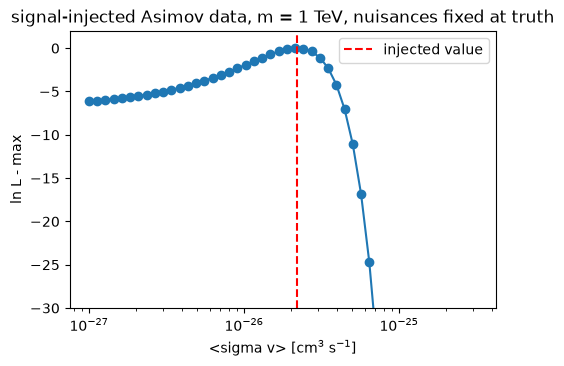

[wall time: 570 ms]


In [4]:
def loglike(n, mass, sigmav, nu):
    """(B,) log-likelihood relative to the saturated model.  mass / sigmav scalar or (B,), nu (B, 4) or (4,)."""
    nu = torch.as_tensor(nu)
    if nu.ndim == 1:
        nu = nu[None]
    lam = model_log_counts(mass, sigmav, **nuisance_kwargs(nu))
    log_n = torch.where(n > 0, torch.log(n.clamp_min(torch.finfo(n.dtype).tiny)), torch.zeros_like(n))
    term = torch.where(n[None] > 0, n[None] * (lam - log_n[None]), torch.zeros_like(lam))
    return (term - (torch.exp(lam) - n[None])).sum((1, 2, 3))


B = 16 if FAST else 48
sv_scan = torch.logspace(-27, -24.5, B)
t0 = time.time()
ll_batched = loglike(n_sig, M_INJECT, sv_scan, NUISANCE_TRUTH)
t_batched = time.time() - t0
t0 = time.time()
ll_loop = torch.stack([loglike(n_sig, M_INJECT, s, NUISANCE_TRUTH)[0] for s in sv_scan[:4]])
t_loop = (time.time() - t0) / 4 * B
print(f"B = {B}: one batched call {t_batched:.2f} s, a Python loop would take {t_loop:.2f} s; identical results: {torch.allclose(ll_batched[:4], ll_loop)}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.semilogx(npy(sv_scan), npy(ll_batched - ll_batched.max()), "o-")
ax.axvline(SV_INJECT, color="r", ls="--", label="injected value")
ax.set(xlabel="<sigma v> [cm$^3$ s$^{-1}$]", ylabel="ln L - max", title="signal-injected Asimov data, m = 1 TeV, nuisances fixed at truth", ylim=(-30, 2))
ax.legend()

The curve above is the *conditional* likelihood: the nuisance parameters are held at their true
values.  In a real analysis they are unknown, and the information they share with the signal
(the background amplitude in particular) widens the constraint.  That is what profiling tries to accounts for.

## 4. Profiling the nuisance parameters

For every grid point $(m_\chi, \langle\sigma v\rangle)$ the nuisance parameters are set to the values
that maximise the likelihood:

$$\ln\mathcal{L}_\mathrm{prof}(m_\chi, \langle\sigma v\rangle) = \max_{A}\ \ln\mathcal{L}(m_\chi, \langle\sigma v\rangle, A).$$

With the spectral shapes fixed, every component is a **template** $T_k$ scaled by an amplitude
$A_k \ge 0$, so $\lambda = \sum_k A_k T_k + \langle\sigma v\rangle\, T_\mathrm{DM}(m_\chi)$ is linear in the
amplitudes and the Poisson log-likelihood is concave in them.  Its gradient and Hessian are closed
form,

$$\frac{\partial \ln\mathcal{L}}{\partial A_k} = \sum_r \Big(\frac{n_r}{\lambda_r} - 1\Big) T_{k,r}, \qquad
  \frac{\partial^2 \ln\mathcal{L}}{\partial A_k\, \partial A_l} = -\sum_r \frac{n_r}{\lambda_r^2}\, T_{k,r}\, T_{l,r},$$

so a damped Newton iteration converges in a few steps for all grid points at once; nothing is
re-evaluated through the forward operator.

**Background systematics.**  With $3\times10^6$ background counts the statistical uncertainty on the
background normalisation is 0.06 %; real instruments do not know their background that well.  The
standard treatment in CTAO sensitivity studies is one background normalisation **per energy bin**,
free to float but constrained by a Gaussian of width $\sigma_\mathrm{sys}$ (1 % here), which enters the
likelihood as $-\tfrac12\sum_e (A_{\mathrm{CCR},e} - 1)^2/\sigma_\mathrm{sys}^2$.  `profile(..., sys=None)`
uses a single global background amplitude (statistics only); `profile(..., sys=0.01)` uses the
per-energy-bin version.

In [5]:
# ---- reconstructed-space templates (expected counts for unit amplitude), built once
with torch.no_grad():
    T_gc = torch.exp(op(gc.eval_log_on_geom(spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.})))
    T_iso = torch.exp(op(log_iso[0]))
    T_ccr = torch.exp(log_ccr)                                                     # already reconstructed space
    n_m, n_s = (6, 16) if FAST else (10, 28)
    mass_grid = torch.logspace(np.log10(0.3), np.log10(30.), n_m)
    lsv_grid = torch.linspace(-27.0, -24.5, n_s)
    sv_grid = 10.0 ** lsv_grid
    SV_REF = 1e-26
    log_dm_true = dm.eval_log_on_geom(spectral_params={"mass": mass_grid, "sigmav": SV_REF, "ratios": {"W+W-": 1.}},
                                      spatial_params={"alpha": 0.17}, squeeze=False)          # (n_m, E_t, lon_t, lat_t)
    T_dm = torch.exp(op(log_dm_true)) / SV_REF                                      # (n_m, E, lon, lat): counts per unit <sigma v>
print("templates: GC %.4g, iso %.4g, CCR %.4g counts; DM at 1e-26 and %s TeV: %s counts" % (
    T_gc.sum(), T_iso.sum(), T_ccr.sum(), [f"{m:.2g}" for m in npy(mass_grid[[0, n_m // 2, -1]])],
    [f"{c:.3g}" for c in npy(T_dm.sum((1, 2, 3))[[0, n_m // 2, -1]] * SV_REF)]))


def profile(n, mass_idx, sigmav, sys=None, max_iter=30, tol=1e-8, verbose=True):
    """Profile the template amplitudes for every element of the flattened (mass index, sigma v) grid.

    sys: None -> one global background amplitude (statistics only);
         float -> one background amplitude per energy bin with a Gaussian constraint of that width.
    Returns (lnL_prof (B,), amplitudes (B, K)) with K = 2 + 1 or 2 + E; lnL is relative to the saturated model.
    Convergence: the predicted lnL gain of the next Newton step (the Newton decrement) is below tol for
    every row; the test statistics below are differences of lnL, so this is the quantity that matters.
    """
    mass_idx = torch.as_tensor(mass_idx).reshape(-1)
    sigmav = torch.as_tensor(sigmav).reshape(-1)
    B = max(mass_idx.numel(), sigmav.numel())
    mass_idx, sigmav = mass_idx.expand(B), sigmav.expand(B)
    E = T_ccr.shape[0]
    n_ccr = E if sys is not None else 1
    K = 2 + n_ccr
    S = sigmav[:, None, None, None] * T_dm[mass_idx]                                 # fixed signal term, (B, E, lon, lat)
    log_n = torch.where(n > 0, torch.log(n.clamp_min(torch.finfo(n.dtype).tiny)), torch.zeros_like(n))

    def rate(A):
        a_ccr = A[:, 2:] if sys is not None else A[:, 2:3].expand(B, E)
        return A[:, 0, None, None, None] * T_gc + A[:, 1, None, None, None] * T_iso + a_ccr[:, :, None, None] * T_ccr + S

    def lnL(A):
        lam = rate(A)
        term = torch.where(n > 0, n * (torch.log(lam) - log_n), torch.zeros_like(lam))
        out = (term - (lam - n)).sum((1, 2, 3))
        if sys is not None:
            out = out - 0.5 * ((A[:, 2:] - 1.0) ** 2).sum(1) / sys ** 2
        return out

    def grad_hess(A):
        lam = rate(A)
        r = n / lam - 1.0                                                            # (B, E, lon, lat)
        w = n / lam ** 2
        g = torch.empty(B, K)
        H = torch.zeros(B, K, K)
        g[:, 0] = (r * T_gc).sum((1, 2, 3))
        g[:, 1] = (r * T_iso).sum((1, 2, 3))
        g_ccr_e = (r * T_ccr).sum((2, 3))                                            # (B, E)
        H[:, 0, 0] = -(w * T_gc * T_gc).sum((1, 2, 3))
        H[:, 1, 1] = -(w * T_iso * T_iso).sum((1, 2, 3))
        H[:, 0, 1] = H[:, 1, 0] = -(w * T_gc * T_iso).sum((1, 2, 3))
        h_gc_e = -(w * T_gc * T_ccr).sum((2, 3))                                     # (B, E)
        h_iso_e = -(w * T_iso * T_ccr).sum((2, 3))
        h_ee = -(w * T_ccr * T_ccr).sum((2, 3))
        if sys is not None:
            g[:, 2:] = g_ccr_e - (A[:, 2:] - 1.0) / sys ** 2
            H[:, 0, 2:] = H[:, 2:, 0] = h_gc_e
            H[:, 1, 2:] = H[:, 2:, 1] = h_iso_e
            H[:, 2:, 2:] = torch.diag_embed(h_ee - 1.0 / sys ** 2)
        else:
            g[:, 2] = g_ccr_e.sum(1)
            H[:, 0, 2] = H[:, 2, 0] = h_gc_e.sum(1)
            H[:, 1, 2] = H[:, 2, 1] = h_iso_e.sum(1)
            H[:, 2, 2] = h_ee.sum(1)
        return g, H

    t0 = time.time()
    A = torch.ones(B, K)                                                             # truth = unit amplitudes
    ll = lnL(A)
    damping = torch.full((B,), 1e-6)
    eye = torch.eye(K)
    for it in range(max_iter):
        g, H = grad_hess(A)
        # active set: an amplitude at zero whose gradient points further down stays fixed at zero this step
        bound = (A <= 0) & (g < 0)
        g_eff = torch.where(bound, torch.zeros_like(g), g)
        H_eff = torch.where(bound[:, :, None] | bound[:, None, :], torch.zeros_like(H), H) - torch.diag_embed(bound.to(H.dtype))
        step = torch.linalg.solve(-H_eff + damping[:, None, None] * eye, g_eff[..., None])[..., 0]
        dec = 0.5 * (g_eff * step).sum(1)                                            # predicted lnL gain (Newton decrement)
        done = dec < tol
        if bool(done.all()):
            break
        trial = (A + step).clamp_min(0.0)                                            # amplitudes are non-negative
        ll_trial = lnL(trial)
        for _ in range(8):                                                           # per-row backtracking
            worse = ~done & (ll_trial < ll - 1e-9)
            if not bool(worse.any()):
                break
            step = torch.where(worse[:, None], 0.5 * step, step)
            trial = (A + step).clamp_min(0.0)
            ll_trial = torch.where(worse, lnL(trial), ll_trial)
            damping = torch.where(worse, damping * 10, damping)
        accept = ~done & (ll_trial >= ll - 1e-9)
        A = torch.where(accept[:, None], trial, A)
        ll = torch.where(accept, ll_trial, ll)
        damping = torch.where(accept, damping * 0.3, damping).clamp(1e-9, 1e9)
    dec_max = float(dec.max())
    if verbose:
        status = "converged" if dec_max < tol else "NOT converged"
        print(f"profiled {B} grid points ({'per-energy-bin background, sigma_sys = %g' % sys if sys is not None else 'global background amplitude'}): "
              f"{it + 1} Newton iterations, {time.time() - t0:.1f} s, largest remaining lnL gain {dec_max:.1e} ({status})")
    return ll, A


flat_i = torch.arange(n_m).repeat_interleave(n_s)                                    # row-major (mass, sigma v) grid
flat_s = sv_grid.repeat(n_m)

results = {}
for label, sys in (("stat", None), ("sys1pc", 0.01)):
    for data_label, n in (("bkg", n_bkg), ("sig", n_sig)):
        ll0, A0 = profile(n, torch.arange(n_m), torch.zeros(n_m), sys=sys)          # sigma v = 0 at each mass
        llp, Ap = profile(n, flat_i, flat_s, sys=sys)
        results[(label, data_label)] = dict(ll0=ll0, llp=llp.reshape(n_m, n_s), A0=A0, Ap=Ap.reshape(n_m, n_s, -1))
A0_sig = results[("stat", "sig")]["A0"]
print("\nsignal data fitted without DM (statistics only): amplitudes GC %.4f, iso %.4f, CCR %.5f at m = 1 TeV row"
      % tuple(npy(A0_sig[int(torch.argmin((mass_grid - 1).abs()))])))

templates: GC 2.076e+04, iso 2891, CCR 3.003e+06 counts; DM at 1e-26 and ['0.3', '3.9', '30'] TeV: ['1.58e+03', '1.13e+03', '133'] counts
profiled 10 grid points (global background amplitude): 1 Newton iterations, 0.0 s, largest remaining lnL gain 7.1e-29 (converged)


profiled 280 grid points (global background amplitude): 4 Newton iterations, 0.9 s, largest remaining lnL gain 9.6e-09 (converged)
profiled 10 grid points (global background amplitude): 3 Newton iterations, 0.0 s, largest remaining lnL gain 3.5e-15 (converged)


profiled 280 grid points (global background amplitude): 4 Newton iterations, 1.0 s, largest remaining lnL gain 9.4e-09 (converged)
profiled 10 grid points (per-energy-bin background, sigma_sys = 0.01): 1 Newton iterations, 0.0 s, largest remaining lnL gain 9.8e-28 (converged)


profiled 280 grid points (per-energy-bin background, sigma_sys = 0.01): 4 Newton iterations, 0.9 s, largest remaining lnL gain 9.9e-09 (converged)
profiled 10 grid points (per-energy-bin background, sigma_sys = 0.01): 3 Newton iterations, 0.0 s, largest remaining lnL gain 4.1e-15 (converged)


profiled 280 grid points (per-energy-bin background, sigma_sys = 0.01): 4 Newton iterations, 0.9 s, largest remaining lnL gain 5.4e-09 (converged)

signal data fitted without DM (statistics only): amplitudes GC 1.0061, iso 1.2147, CCR 1.00143 at m = 1 TeV row


[wall time: 3.9 s]


All fits (two data sets, with and without the systematic, at $\langle\sigma v\rangle = 0$ and over the
full grid) converge in a handful of Newton steps.  On the background-only Asimov data the
$\langle\sigma v\rangle = 0$ fit returns unit amplitudes, as it must; on the signal-injected data the
background and the isotropic component absorb part of the injected photons when no DM term is allowed.

## 5. Results

### 5.1 Median expected upper limit (background-only Asimov data)

The profile-likelihood-ratio test statistic for an upper limit (Cowan et al. 2011, eq. 14) is

$$q_{\mu} = -2\ln\frac{\mathcal{L}_\mathrm{prof}(\mu)}{\mathcal{L}_\mathrm{prof}(\hat\mu)},\qquad \mu = \langle\sigma v\rangle,$$

with $\hat\mu$ the best fit (zero at the physical boundary for background-only data).  Under
Wilks' theorem $q_\mu$ follows a half-$\chi^2_1$ distribution for one-sided tests, and the 95 % CL
upper limit is where $q_\mu = 2.71$.  Because the data are Asimov, this is the **median** expected
limit; real data would scatter around it this projection.

expected limit at 1 TeV: statistics only 1.69e-26, with 1% systematic 1.86e-26 cm^3/s   (injected 2.2e-26)


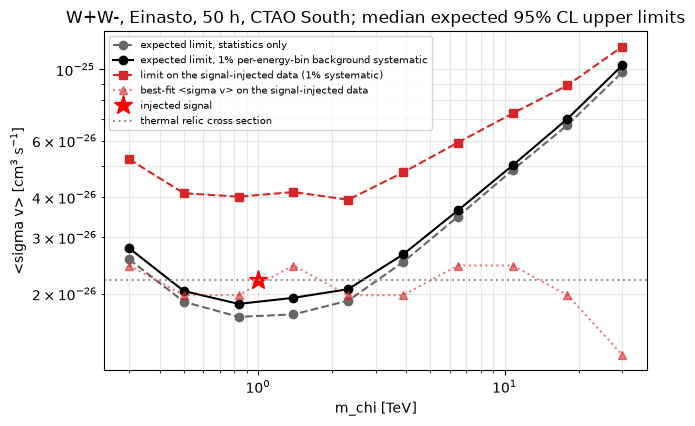

[wall time: 156 ms]


In [6]:
Q95 = 2.71            # one-sided 95% CL, half-chi2 with one degree of freedom


def upper_limit(llp, ll0, sv):
    """95% CL upper limit per mass row from the profile likelihood on the sigma v grid.
    llp (n_m, n_s), ll0 (n_m,) at sigma v = 0 (the physical boundary).  Interpolated in log sigma v."""
    best = torch.maximum(llp.max(1).values, ll0)             # hat mu may sit on the boundary
    q = 2.0 * (best[:, None] - llp)                           # (n_m, n_s)
    ul = torch.empty(llp.shape[0])
    for i in range(llp.shape[0]):
        qi, lsi = npy(q[i]), npy(torch.log10(sv))
        j0 = int(np.argmax(npy(llp[i]))) if llp[i].max() > ll0[i] else 0
        qi, lsi = qi[j0:], lsi[j0:]                           # only above the best fit
        above = np.flatnonzero(qi > Q95)
        if len(above) == 0:
            ul[i] = float("nan")                              # grid too short: raise lsv_grid
        elif above[0] == 0:
            ul[i] = 10 ** lsi[0]
        else:
            k = above[0]
            ul[i] = 10 ** np.interp(Q95, qi[k - 1:k + 1], lsi[k - 1:k + 1])
    return ul


ul = {key: upper_limit(r["llp"], r["ll0"], sv_grid) for key, r in results.items()}
best_sig = {lab: sv_grid[results[(lab, "sig")]["llp"].argmax(1)] for lab in ("stat", "sys1pc")}
k1 = int(torch.argmin((mass_grid - 1).abs()))

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.loglog(npy(mass_grid), npy(ul[("stat", "bkg")]), "o--", color="0.4", label="expected limit, statistics only")
ax.loglog(npy(mass_grid), npy(ul[("sys1pc", "bkg")]), "o-", color="k", label="expected limit, 1% per-energy-bin background systematic")
ax.loglog(npy(mass_grid), npy(ul[("sys1pc", "sig")]), "s--", color="tab:red", label="limit on the signal-injected data (1% systematic)")
ax.loglog(npy(mass_grid), npy(best_sig["sys1pc"]), "^:", color="tab:red", alpha=0.6, label="best-fit <sigma v> on the signal-injected data")
ax.plot(M_INJECT, SV_INJECT, "r*", ms=14, label="injected signal")
ax.axhline(2.2e-26, color="0.6", ls=":", label="thermal relic cross section")
ax.set(xlabel="m_chi [TeV]", ylabel="<sigma v> [cm$^3$ s$^{-1}$]",
       title="W+W-, Einasto, 50 h, CTAO South; median expected 95% CL upper limits")
ax.legend(fontsize=7, loc="upper left")
ax.grid(alpha=0.3, which="both")
print("expected limit at 1 TeV: statistics only %.2e, with 1%% systematic %.2e cm^3/s   (injected %.1e)"
      % (ul[("stat", "bkg")][k1], ul[("sys1pc", "bkg")][k1], SV_INJECT))

In the figure:

* the grey dashed curve is the statistics-only sensitivity, the black one the sensitivity with the
  1 % per-energy-bin background systematic.  The systematic matters most where the background counts
  per energy bin are large enough that 1 % of them exceeds the Poisson fluctuation, i.e. at low
  energies and hence low masses; it matters less at high masses, where the DM spectrum sits in
  energy bins with fewer background counts;
* on the signal-injected data the limit (red dashed) rises above the injected value near 1 TeV, as
  it must, and the best fit (red dotted) recovers the injected point.  Far from 1 TeV the fit
  reinterprets part of the injected photons as a wrong-mass signal, which is why the red limit
  stays above the black one everywhere.

### 5.2 Detection significance and confidence region (signal-injected Asimov data)

The discovery test statistic compares the best fit with the background-only hypothesis,

$$q_0 = 2\,\big[\ln\mathcal{L}_\mathrm{prof}(\hat m_\chi, \widehat{\langle\sigma v\rangle}) - \ln\mathcal{L}_\mathrm{prof}(\langle\sigma v\rangle = 0)\big],$$

and $\sqrt{q_0}$ is the approximate one-sided Gaussian significance (the mass is a nuisance under the
null, so this ignores the look-elsewhere effect).  Contours of $2\,\Delta\ln\mathcal{L}_\mathrm{prof}$
at 2.30 and 5.99 are the 68 % and 95 % confidence regions for the two parameters of interest.
Both are shown for the fit with the 1 % systematic.

best fit: m = 0.835 TeV, <sigma v> = 1.98e-26 cm^3/s
q0 = 3.6 -> ~1.9 sigma with the 1% systematic   (statistics only: q0 = 4.3 -> ~2.1 sigma)


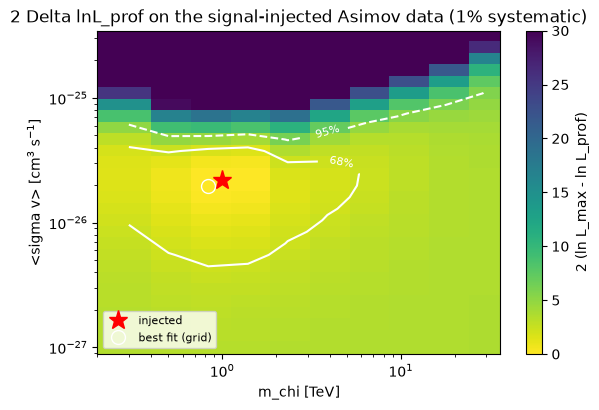

[wall time: 186 ms]


In [7]:
llp_sig, ll0_sig = results[("sys1pc", "sig")]["llp"], results[("sys1pc", "sig")]["ll0"]
i_best, j_best = np.unravel_index(int(llp_sig.argmax()), llp_sig.shape)
q0 = 2.0 * float(llp_sig.max() - ll0_sig.max())
q0_stat = 2.0 * float(results[("stat", "sig")]["llp"].max() - results[("stat", "sig")]["ll0"].max())
print(f"best fit: m = {float(mass_grid[i_best]):.3g} TeV, <sigma v> = {float(sv_grid[j_best]):.2e} cm^3/s")
print(f"q0 = {q0:.1f} -> ~{math.sqrt(max(q0, 0)):.1f} sigma with the 1% systematic   (statistics only: q0 = {q0_stat:.1f} -> ~{math.sqrt(max(q0_stat, 0)):.1f} sigma)")

d2 = 2.0 * (llp_sig.max() - llp_sig)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
pcm = ax.pcolormesh(npy(mass_grid), npy(sv_grid), npy(d2).T, shading="auto", vmin=0, vmax=30, cmap="viridis_r")
cs = ax.contour(npy(mass_grid), npy(sv_grid), npy(d2).T, levels=[2.30, 5.99], colors=["w", "w"], linestyles=["-", "--"])
ax.clabel(cs, fmt={2.30: "68%", 5.99: "95%"}, fontsize=8)
ax.plot(M_INJECT, SV_INJECT, "r*", ms=14, label="injected")
ax.plot(float(mass_grid[i_best]), float(sv_grid[j_best]), "wo", mfc="none", ms=10, label="best fit (grid)")
ax.set(xscale="log", yscale="log", xlabel="m_chi [TeV]", ylabel="<sigma v> [cm$^3$ s$^{-1}$]",
       title="2 Delta lnL_prof on the signal-injected Asimov data (1% systematic)")
plt.colorbar(pcm, ax=ax, label="2 (ln L_max - ln L_prof)")
ax.legend(loc="lower left", fontsize=8)

### 5.3 A Laplace approximation

The template fit above never needed autograd, but the general model does: with the point-source
index free, the Hessian of the log-likelihood at the best fit is one `torch.autograd` call.  Its
inverse is the covariance of the Gaussian (Laplace) approximation, which is what importance-sampling
and Fisher-forecast pipelines start from.  Comparing the Gaussian in $\log_{10}\langle\sigma v\rangle$
with the statistics-only profile at the best-fit mass shows how far the approximation can be
trusted: good near the maximum, too optimistic in the tail towards zero signal, where the likelihood
is not parabolic.

general-model Newton refinement: 6 steps, max |dlnL/dtheta| = 1.3e-04
  log10_sv  =  -25.6611 +/- 0.2133
  logA_gc   =    0.0003 +/- 0.0103
  index     =    2.2998 +/- 0.0076
  logA_iso  =    0.1128 +/- 0.4689
  logA_ccr  =   -0.0001 +/- 0.0011
  -> <sigma v> = 2.18e-26 (+1.4e-26 / -8.5e-27) cm^3/s, injected 2.2e-26


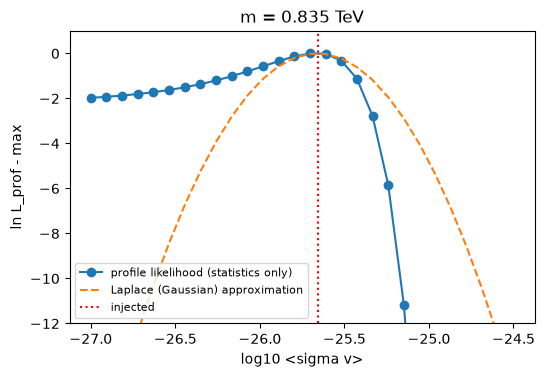

[wall time: 2.1 s]


In [8]:
FREE = ("log10_sv",) + NUISANCE
res_stat = results[("stat", "sig")]
i_s, j_s = np.unravel_index(int(res_stat["llp"].argmax()), res_stat["llp"].shape)
m_fix = float(mass_grid[i_s])


def f(vec, n=n_sig):
    """ln L of the general model at fixed best-fit mass as a function of (log10 sigma v, log amplitudes, index)."""
    return loglike(n, m_fix, 10.0 ** vec[0], vec[1:])[0]


A_hat = res_stat["Ap"][i_s, j_s]                                  # template-fit amplitudes (GC, iso, CCR)
vec = torch.tensor([float(torch.log10(sv_grid[j_s])), math.log(float(A_hat[0])), 2.3, math.log(float(A_hat[1])), math.log(float(A_hat[2]))])
for it in range(6):                                               # a few Newton steps refine the grid optimum
    grad = torch.autograd.functional.jacobian(f, vec)
    H = torch.autograd.functional.hessian(f, vec)
    step = -torch.linalg.solve(H, grad)
    if float(f(vec + step)) < float(f(vec)):                      # H not negative definite this far out: halve the step
        step = 0.5 * step
    vec = vec + step
    if float(grad.abs().max()) < 1e-6:
        break
print(f"general-model Newton refinement: {it + 1} steps, max |dlnL/dtheta| = {float(torch.autograd.functional.jacobian(f, vec).abs().max()):.1e}")
H = torch.autograd.functional.hessian(f, vec)
cov = torch.linalg.inv(-H)
sig = torch.sqrt(torch.diag(cov))
for k, v, s in zip(FREE, npy(vec), npy(sig)):
    print(f"  {k:9s} = {v:9.4f} +/- {s:.4f}")
print(f"  -> <sigma v> = {10 ** float(vec[0]):.2e} (+{(10 ** (float(vec[0]) + float(sig[0])) - 10 ** float(vec[0])):.1e} / -{(10 ** float(vec[0]) - 10 ** (float(vec[0]) - float(sig[0]))):.1e}) cm^3/s, injected {SV_INJECT:.1e}")

prof = res_stat["llp"][i_s]
x = npy(lsv_grid)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(x, npy(prof - prof.max()), "o-", label="profile likelihood (statistics only)")
ax.plot(x, -0.5 * ((x - float(vec[0])) / float(sig[0])) ** 2, "--", label="Laplace (Gaussian) approximation")
ax.axvline(math.log10(SV_INJECT), color="r", ls=":", label="injected")
ax.set(xlabel="log10 <sigma v>", ylabel="ln L_prof - max", ylim=(-12, 1), title=f"m = {m_fix:.3g} TeV")
ax.legend(fontsize=8)

### 5.4 One Poisson realisation

Everything above used Asimov data, i.e. median outcomes.  Repeating the fit on a single Poisson
realisation of the signal-injected sky shows the statistical scatter a real observation would have:
the best fit moves, the significance fluctuates, and the limit on the realisation can fall on either
side of the median expectation.

Poisson realisation: best fit m = 2.32 TeV, <sigma v> = 3.75e-26, q0 = 8.8 (~3.0 sigma)
Asimov            : best fit m = 0.835 TeV, <sigma v> = 1.98e-26, q0 = 3.6 (~1.9 sigma)


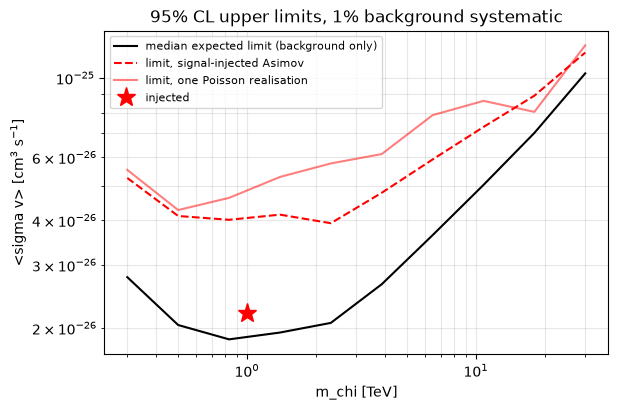

[wall time: 934 ms]


In [9]:
ll0_p, _ = profile(n_sig_poisson, torch.arange(n_m), torch.zeros(n_m), sys=0.01, verbose=False)
llp_p, _ = profile(n_sig_poisson, flat_i, flat_s, sys=0.01, verbose=False)
llp_p = llp_p.reshape(n_m, n_s)
ip, jp = np.unravel_index(int(llp_p.argmax()), llp_p.shape)
q0_p = 2.0 * float(llp_p.max() - ll0_p.max())
ul_p = upper_limit(llp_p, ll0_p, sv_grid)
print(f"Poisson realisation: best fit m = {float(mass_grid[ip]):.3g} TeV, <sigma v> = {float(sv_grid[jp]):.2e}, q0 = {q0_p:.1f} (~{math.sqrt(max(q0_p, 0)):.1f} sigma)")
print(f"Asimov            : best fit m = {float(mass_grid[i_best]):.3g} TeV, <sigma v> = {float(sv_grid[j_best]):.2e}, q0 = {q0:.1f} (~{math.sqrt(max(q0, 0)):.1f} sigma)")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(npy(mass_grid), npy(ul[("sys1pc", "bkg")]), "k-", label="median expected limit (background only)")
ax.loglog(npy(mass_grid), npy(ul[("sys1pc", "sig")]), "r--", label="limit, signal-injected Asimov")
ax.loglog(npy(mass_grid), npy(ul_p), "r-", alpha=0.5, label="limit, one Poisson realisation")
ax.plot(M_INJECT, SV_INJECT, "r*", ms=14, label="injected")
ax.set(xlabel="m_chi [TeV]", ylabel="<sigma v> [cm$^3$ s$^{-1}$]", title="95% CL upper limits, 1% background systematic")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")